<a href="https://colab.research.google.com/github/SachiniKalansooriya/Dengue_Ensemble_Forecasting/blob/main/Dengue_Ensemble_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pyreadr xgboost lightgbm catboost statsmodels shap streamlit joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 42.4 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 58.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 87.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [streamlit]


In [2]:
import os, pyreadr, urllib.request
os.makedirs("data", exist_ok=True)
url = "https://raw.githubusercontent.com/thiyangt/denguedatahub/master/data/srilanka_weekly_data.rda"
urllib.request.urlretrieve(url, "srilanka_weekly_data.rda")
dengue = list(pyreadr.read_r("srilanka_weekly_data.rda").values())[0]
dengue.to_csv("data/dengue_weekly.csv", index=False)

In [20]:
import pandas as pd

In [21]:
districts = {
    "Ampara": (7.30, 81.67), "Anuradhapura": (8.31, 80.40), "Badulla": (6.99, 81.06),
    "Batticaloa": (7.73, 81.69), "Colombo": (6.93, 79.85), "Galle": (6.05, 80.22),
    "Gampaha": (7.09, 79.99), "Hambanthota": (6.12, 81.12), "Jaffna": (9.66, 80.01),
    "Kalmune": (7.41, 81.83), "Kalutara": (6.58, 79.96), "Kandy": (7.29, 80.63),
    "Kegalle": (7.25, 80.35), "Kilinochchi": (9.39, 80.40), "Kurunegala": (7.49, 80.36),
    "Mannar": (8.98, 79.90), "Matale": (7.47, 80.62), "Matara": (5.95, 80.54),
    "Monaragala": (6.87, 81.35), "Mullaitivu": (9.27, 80.81), "NuwaraEliya": (6.97, 80.78),
    "Polonnaruwa": (7.94, 81.00), "Puttalam": (8.04, 79.83), "Ratnapura": (6.68, 80.40),
    "Trincomalee": (8.59, 81.21), "Vavuniya": (8.75, 80.50),
}

In [22]:
print(len(districts), "districts")

26 districts


In [23]:
import os, time, requests
from datetime import date, timedelta

os.makedirs("data/weather_raw", exist_ok=True)
end = (date.today() - timedelta(days=7)).isoformat()   # archive data lags a few days

for name, (lat, lon) in districts.items():
    path = f"data/weather_raw/{name}.csv"
    if os.path.exists(path):
        continue                                          # already downloaded
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": "2006-12-01", "end_date": end,
        "daily": "precipitation_sum,temperature_2m_mean,relative_humidity_2m_mean",
        "timezone": "Asia/Colombo",
    }
    for attempt in range(5):
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
        if r.status_code == 200:
            daily = pd.DataFrame(r.json()["daily"])
            daily["district"] = name
            daily.to_csv(path, index=False)
            print("done:", name, len(daily), "days")
            break
        print(name, "error", r.status_code, "- waiting 60 s")
        time.sleep(60)
    time.sleep(20)

done: Ampara 7290 days
done: Anuradhapura 7290 days
done: Badulla 7290 days
done: Batticaloa 7290 days
done: Colombo 7290 days
done: Galle 7290 days
done: Gampaha 7290 days
done: Hambanthota 7290 days
done: Jaffna 7290 days
done: Kalmune 7290 days
done: Kalutara 7290 days
done: Kandy 7290 days
done: Kegalle 7290 days
done: Kilinochchi 7290 days
done: Kurunegala 7290 days
done: Mannar 7290 days
done: Matale 7290 days
done: Matara 7290 days
done: Monaragala 7290 days
done: Mullaitivu 7290 days
done: NuwaraEliya 7290 days
done: Polonnaruwa 7290 days
done: Puttalam 7290 days
done: Ratnapura 7290 days
done: Trincomalee 7290 days
done: Vavuniya 7290 days


In [25]:
import glob

weather = pd.concat([pd.read_csv(f) for f in glob.glob("data/weather_raw/*.csv")])
weather["time"] = pd.to_datetime(weather["time"])

def parse_dates(col):
    us_format  = pd.to_datetime(col, format="%m/%d/%Y", errors="coerce")
    iso_format = pd.to_datetime(col, format="%Y-%m-%d", errors="coerce")
    return us_format.fillna(iso_format)

dengue["start"] = parse_dates(dengue["start.date"])
dengue["end"]   = parse_dates(dengue["end.date"])
print("Dates that could not be read:", dengue["start"].isna().sum())

# give every day the start date of the dengue week it belongs to
weeks = dengue[["start", "end"]].drop_duplicates().sort_values("start")
weather = pd.merge_asof(weather.sort_values("time"), weeks,
                        left_on="time", right_on="start", direction="backward")
weather = weather[weather["time"] <= weather["end"]]

weekly = (weather.groupby(["district", "start"])
          .agg(rain_mm=("precipitation_sum", "sum"),
               temp_c=("temperature_2m_mean", "mean"),
               humidity=("relative_humidity_2m_mean", "mean"))
          .reset_index())
weekly.to_csv("data/weather_weekly.csv", index=False)

data = dengue.merge(weekly, on=["district", "start"], how="left")
data.to_csv("data/dengue_weather.csv", index=False)
print(data.shape)
print(data[["rain_mm", "temp_c", "humidity"]].isna().mean())
data.head()

Dates that could not be read: 0
(26753, 11)
rain_mm     0.0
temp_c      0.0
humidity    0.0
dtype: float64


,year,week,start.date,end.date,district,cases,start,end,rain_mm,temp_c,humidity
0,2006.0,52.0,12/23/2006,12/29/2006,Colombo,71.0,2006-12-23,2006-12-29,1.4,25.885714,74.571429
1,2006.0,52.0,12/23/2006,12/29/2006,Gampaha,12.0,2006-12-23,2006-12-29,1.4,25.828571,73.857143
2,2006.0,52.0,12/23/2006,12/29/2006,Kalutara,12.0,2006-12-23,2006-12-29,8.6,25.828571,80.428571
3,2006.0,52.0,12/23/2006,12/29/2006,Kandy,20.0,2006-12-23,2006-12-29,9.5,21.571429,85.000000
4,2006.0,52.0,12/23/2006,12/29/2006,Matale,4.0,2006-12-23,2006-12-29,5.1,23.271429,84.000000


In [26]:
## Exploratory Data Analysis

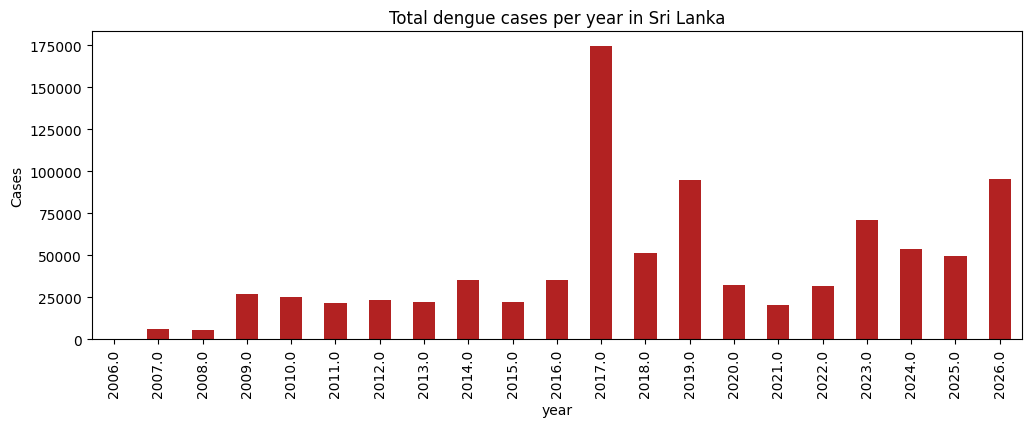

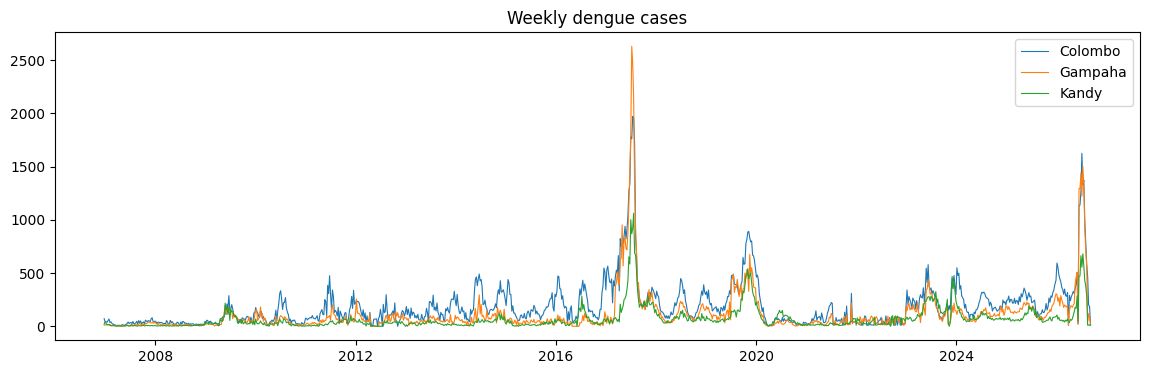

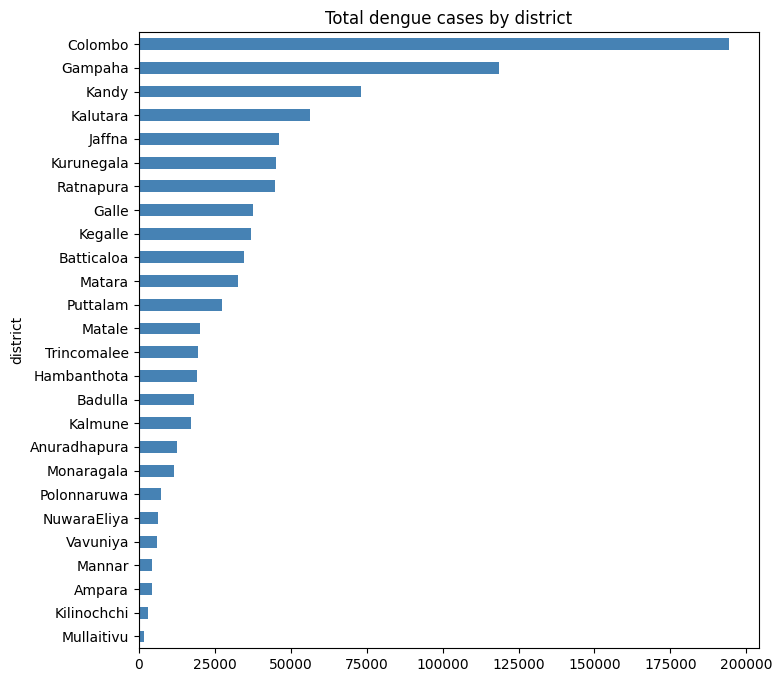

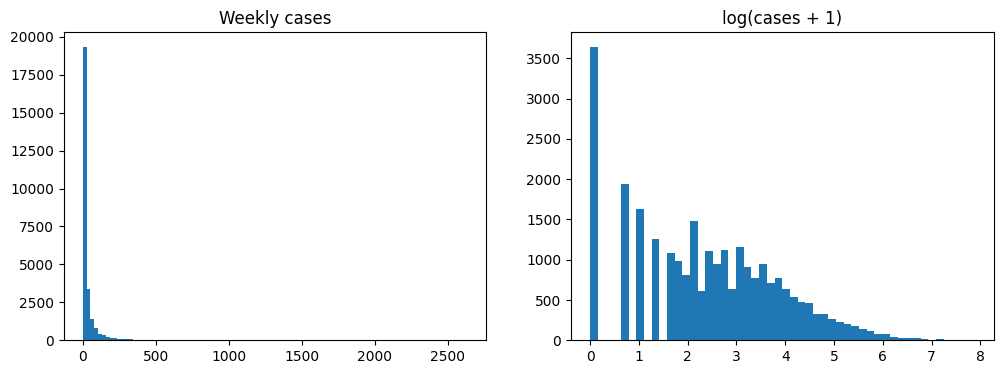

In [27]:
import matplotlib.pyplot as plt
import numpy as np

data = data.sort_values(["district", "start"]).reset_index(drop=True)

# 1. Total cases per year
data.groupby("year")["cases"].sum().plot(kind="bar", figsize=(12, 4), color="firebrick")
plt.title("Total dengue cases per year in Sri Lanka"); plt.ylabel("Cases"); plt.show()

# 2. Weekly cases for three districts
fig, ax = plt.subplots(figsize=(14, 4))
for d in ["Colombo", "Gampaha", "Kandy"]:
    s = data[data["district"] == d]
    ax.plot(s["start"], s["cases"], label=d, linewidth=0.8)
ax.set_title("Weekly dengue cases"); ax.legend(); plt.show()

# 3. Total cases by district
data.groupby("district")["cases"].sum().sort_values().plot(kind="barh", figsize=(8, 8), color="steelblue")
plt.title("Total dengue cases by district"); plt.show()

# 4. Distribution of weekly cases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data["cases"], bins=100); axes[0].set_title("Weekly cases")
axes[1].hist(np.log1p(data["cases"]), bins=50); axes[1].set_title("log(cases + 1)")
plt.show()

Chart 1: Total cases per year

2017 was by far the worst year, with about 175,000 cases, more than 1.8 times any other year. The next highest years are 2019 and 2026 (about 95,000 each), followed by 2023 (about 71,000). The 2006 bar is almost empty because the data starts in late December 2006, and 2026 only includes data up to September, so the real 2026 total will be higher. Cases were low from 2020 to 2022 and have risen again since 2023. This shows that dengue varies greatly from year to year.

Chart 2: Weekly dengue cases

Colombo, Gampaha and Kandy rise and fall at the same times, so outbreaks affect these districts together. The largest weekly spike was in Gampaha during the 2017 outbreak, at about 2,600 cases in one week, while Colombo reached about 2,000. Other clear outbreaks appear in 2019 and 2026, where Colombo reached about 1,600 cases in one week. Between outbreaks there are several smaller rises every year. Outbreak weeks are many times higher than normal weeks, so they will be the hardest weeks for the models to predict.

Chart 3: Total cases by district

Colombo has the most cases (about 195,000), followed by Gampaha (about 120,000), Kandy (about 73,000) and Kalutara (about 56,000). Jaffna is fifth (about 46,000), so dengue is also a problem in the north, not only in the Western Province. The fewest cases are in Mullaitivu, Kilinochchi, Ampara and Mannar, each with less than about 5,000. The most affected districts are mostly large, densely populated and urban. Because case levels differ so much between districts, the district is used as an input feature.

Chart 4: Distribution of weekly cases

The left histogram shows that almost all weeks have low case counts: the first bar alone holds about 19,500 of the roughly 26,700 district-weeks, while a few outbreak weeks reach over 2,500 cases. This means the data is strongly right-skewed. After applying log(cases + 1) (right), the values are spread more evenly between 0 and about 8. The separate bar at 0 shows about 3,600 weeks with zero cases, mainly in small districts. We predict log(cases + 1) so a few extreme outbreak weeks don't dominate model training.

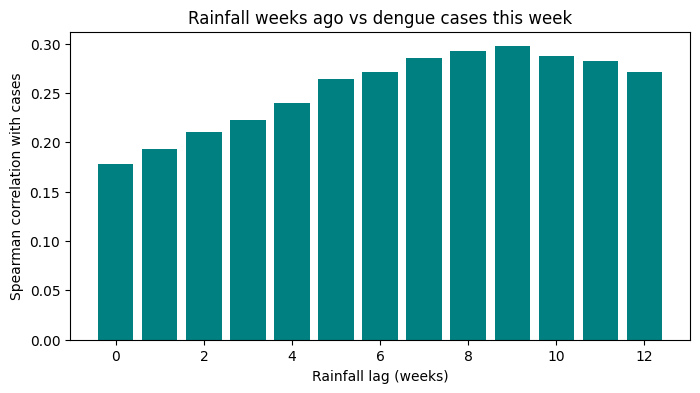

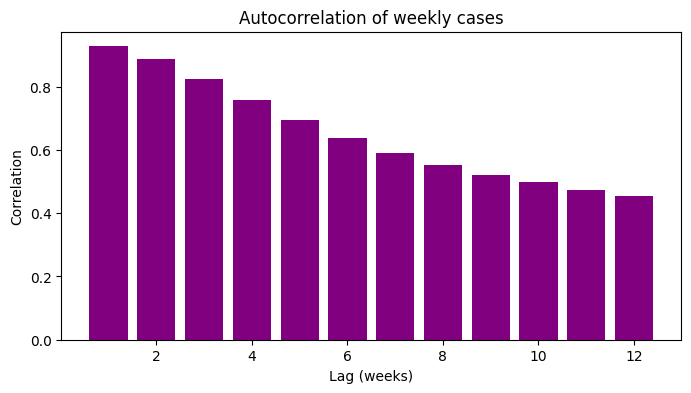

In [28]:
corrs = []
for k in range(0, 13):
    rain_lag = data.groupby("district")["rain_mm"].shift(k)
    corrs.append(data["cases"].corr(rain_lag, method="spearman"))
plt.figure(figsize=(8, 4)); plt.bar(range(0, 13), corrs, color="teal")
plt.xlabel("Rainfall lag (weeks)"); plt.ylabel("Spearman correlation with cases")
plt.title("Rainfall weeks ago vs dengue cases this week"); plt.show()

# 6. How much does this week depend on last week?
ac = [data["cases"].corr(data.groupby("district")["cases"].shift(k)) for k in range(1, 13)]
plt.figure(figsize=(8, 4)); plt.bar(range(1, 13), ac, color="purple")
plt.xlabel("Lag (weeks)"); plt.ylabel("Correlation"); plt.title("Autocorrelation of weekly cases"); plt.show()

Chart 5: Rainfall weeks ago vs dengue cases

The correlation between rainfall and dengue cases is lowest for rainfall in the same week (about 0.18) and increases steadily with the lag. It is highest at a lag of 9 weeks (about 0.30), with 8 and 10 weeks almost as high, and then slowly falls. This matches the mosquito life cycle: rain creates breeding places, mosquitoes develop, the virus incubates, and cases are reported weeks later. The correlation is moderate, and part of it may come from both rainfall and dengue following the monsoon seasons, so rainfall alone cannot predict dengue but adds useful information. We therefore use rainfall from 2 to 12 weeks earlier as features.

Chart 6: Autocorrelation of weekly cases

The correlation between this week's cases and last week's is very high, about 0.93. It decreases slowly: about 0.76 after 4 weeks, 0.55 after 8 weeks and 0.46 after 12 weeks. This means dengue cases change gradually and outbreaks build up over several weeks. Because of this, simply predicting "same as last week" will already be very accurate, and our ensemble models must beat this baseline to be useful.